<a href="https://colab.research.google.com/github/wajihabibi/RhombixTechnologies_Tasks/blob/main/A_B_Testing_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**INTRODUCTION**: This project analyzes an A/B test to determine whether Group B performs better than Group A in terms of user conversion. The analysis includes data exploration, conversion rate comparison, statistical hypothesis testing, device-wise analysis, engagement metrics, visualization, and lift calculation.

In [2]:
# IMPORT LIBRARIES

In [32]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

In [17]:
# LOAD DATASET

In [18]:
df = pd.read_csv("ab_testing.csv")

In [33]:
# DATA OVERVIEW

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   User ID     5000 non-null   int64 
 1   Group       5000 non-null   object
 2   Page Views  5000 non-null   int64 
 3   Time Spent  5000 non-null   int64 
 4   Conversion  5000 non-null   object
 5   Device      5000 non-null   object
 6   Location    5000 non-null   object
dtypes: int64(3), object(4)
memory usage: 273.6+ KB


In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df.describe()

,User ID,Page Views,Time Spent
count,5000.000000,5000.000000,5000.000000
mean,14925.159000,7.537600,242.512600
std,2869.153773,4.022465,118.254153
min,10001.000000,1.000000,40.000000
25%,12456.250000,4.000000,137.000000
50%,14858.500000,8.000000,243.000000
75%,17379.750000,11.000000,346.000000
max,19995.000000,14.000000,449.000000


In [22]:
df['Group'].value_counts()

,count
Group,
A,2519
B,2481


In [34]:
# CONVERSION RATE ANALYSIS

In [23]:
df['Conversion'].value_counts()

,count
Conversion,
No,4515
Yes,485


In [24]:
pd.crosstab(df['Group'], df['Conversion'])

Conversion,No,Yes
Group,,
A,2383,136
B,2132,349


In [25]:
conversion_rate = df.groupby('Group')['Conversion'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

conversion_rate

,Conversion
Group,
A,5.398968
B,14.066909


In [26]:
# Statistical Significance Test

In [27]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Group'], df['Conversion'])

chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p_value)

Chi-square: 106.22812337440538
p-value: 6.571736018334222e-25


In [28]:
pd.crosstab(
    [df['Group'], df['Device']],
    df['Conversion']
)

Conversion       No  Yes
Group Device            
A     Desktop  1171   73
      Mobile   1212   63
B     Desktop  1114  180
      Mobile   1018  169

In [29]:
df.groupby('Group')[['Page Views', 'Time Spent']].mean()

,Page Views,Time Spent
Group,,
A,7.581580,241.733227
B,7.492946,243.303910


In [35]:
# CONVERSION RATE VISUALIZATION

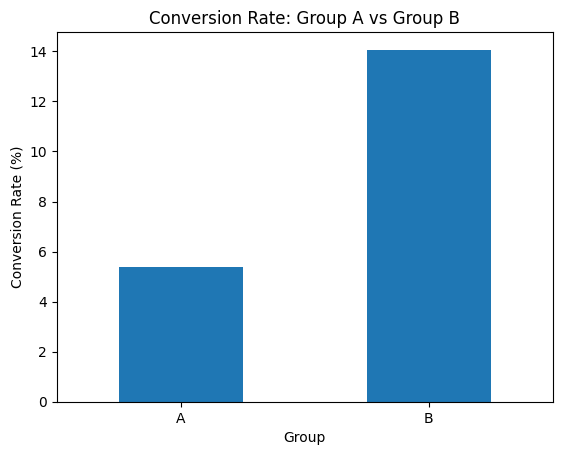

In [30]:
conversion_rate.plot(kind='bar')

plt.title('Conversion Rate: Group A vs Group B')
plt.xlabel('Group')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [36]:
# LIFT ANALYSIS

In [31]:
rate_A = conversion_rate['A']
rate_B = conversion_rate['B']

absolute_lift = rate_B - rate_A
relative_lift = ((rate_B - rate_A) / rate_A) * 100

print("Absolute Lift:", absolute_lift, "%")
print("Relative Lift:", relative_lift, "%")

Absolute Lift: 8.667940660252537 %
Relative Lift: 160.54810678805987 %


**Final Conclusion**: Group B outperformed Group A, with conversion increasing from 5.40% to 14.07%. This represents an 8.67 percentage-point absolute lift and approximately 160.55% relative lift. The Chi-square test resulted in a p-value of 6.57 × 10⁻²⁵, indicating a statistically significant difference between the two groups. Based on this experiment, Group B is the better-performing variant.